In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
df=pd.read_csv('BankNote_Authentication.csv')

In [3]:
df.shape

(1372, 5)

In [4]:
df.isnull().sum()

,0
variance,0
skewness,0
curtosis,0
entropy,0
class,0


In [5]:
df.head(3)

,variance,skewness,curtosis,entropy,class
0,3.6216,8.6661,-2.8073,-0.44699,0
1,4.5459,8.1674,-2.4586,-1.46210,0
2,3.8660,-2.6383,1.9242,0.10645,0


In [6]:
df["class"].value_counts()

,count
class,
0,762
1,610


In [7]:
x=df.drop(columns=["class"])
y=df["class"]
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [8]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.fit_transform(x_test)

In [9]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

In [13]:
ann=Sequential([
    Input(shape=(4,)),
    Dense(16,activation='relu'),
    Dense(8,activation='relu'),
    Dense(1, activation='sigmoid'),
    ])

In [17]:
ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [18]:
history= ann.fit(x_train, y_train, epochs=30, batch_size=25, validation_split=0.2)

Epoch 1/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.5656 - loss: 0.6130 - val_accuracy: 0.5364 - val_loss: 0.5923
Epoch 2/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5998 - loss: 0.5357 - val_accuracy: 0.6045 - val_loss: 0.5216
Epoch 3/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7218 - loss: 0.4752 - val_accuracy: 0.7955 - val_loss: 0.4635
Epoch 4/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8449 - loss: 0.4225 - val_accuracy: 0.8818 - val_loss: 0.4095
Epoch 5/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8962 - loss: 0.3732 - val_accuracy: 0.9318 - val_loss: 0.3563
Epoch 6/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9282 - loss: 0.3259 - val_accuracy: 0.9545 - val_loss: 0.3041
Epoch 7/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9384 - loss: 0.2789 - val_accuracy: 0.9545 - val_loss: 0.2546
Epoch 8/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9532 - loss: 0.2351 - val_accuracy: 0.9773 - val_loss

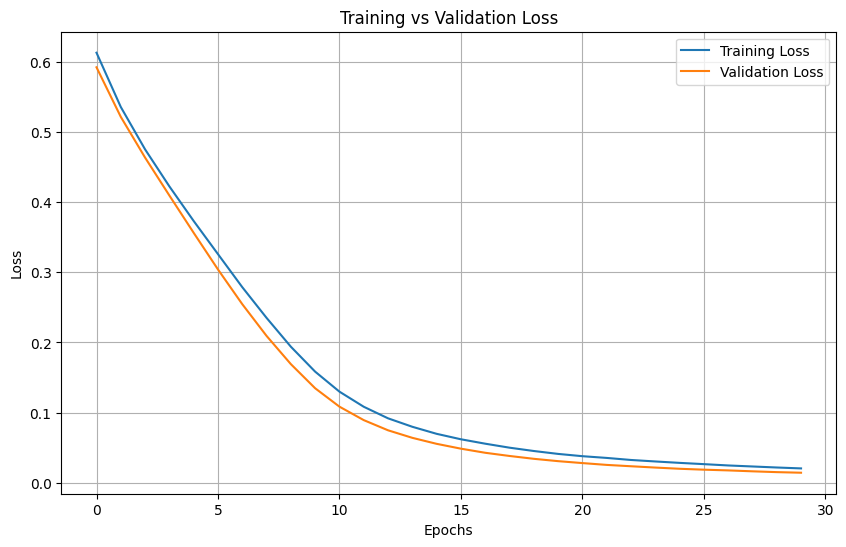

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

In [20]:
loss, acc=ann.evaluate(x_test, y_test, verbose=1)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0224 
